In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
import numpy as np

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import lifelines # pip install lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter

In [ ]:
dataset = pd.read_csv("bone_marrow.csv", index_col=0)
event = dataset["survival_status"]
duration = dataset["survival_time"]
data = dataset.drop(["survival_status","survival_time"], axis = 1)
data

,Rbodymass,Recipientage,extcGvHD,CD34kgx10d6,CD3dkgx10d8,Stemcellsource,Gendermatch,RecipientCMV,Recipientgender,HLAmatch,Antigen,RecipientABO,Allele,HLAgrI,DonorCMV
0,35.0,9.6,1,7.20,5.38,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
1,20.6,4.0,1,4.50,0.41,0.0,0.0,0,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
2,23.4,6.6,1,7.94,0.42,0.0,0.0,1,1.0,0.0,-1.0,-1.0,-1.0,0.0,0.0
3,50.0,18.1,0,4.25,0.14,0.0,0.0,0,0.0,0.0,-1.0,2.0,-1.0,0.0,1.0
4,9.0,1.3,1,51.85,13.05,1.0,0.0,1,0.0,1.0,1.0,2.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182,44.0,12.9,1,11.08,4.39,1.0,0.0,1,1.0,0.0,-1.0,1.0,-1.0,0.0,1.0
183,44.5,13.9,1,4.64,4.47,1.0,0.0,1,0.0,0.0,-1.0,0.0,-1.0,0.0,0.0
184,33.0,10.4,1,7.73,4.73,1.0,0.0,1,0.0,0.0,-1.0,-1.0,-1.0,0.0,1.0
185,24.0,8.0,0,15.41,1.91,1.0,0.0,0,1.0,1.0,1.0,0.0,0.0,1.0,0.0


In [4]:
dataset.columns

Index(['Rbodymass', 'Recipientage', 'extcGvHD', 'CD34kgx10d6', 'CD3dkgx10d8',
       'Stemcellsource', 'Gendermatch', 'RecipientCMV', 'Recipientgender',
       'HLAmatch', 'Antigen', 'RecipientABO', 'Allele', 'HLAgrI', 'DonorCMV',
       'survival_time', 'survival_status'],
      dtype='object')

This notebook is split into two parts

`First part:`

We will perform KMeans clustering. Our objective is to find the optimal number of clusters (K). Methods like DBSCAN do not provide an specific number of clusters but rather rely on the radius value, it also leaves some points unassigned, additionally, methods like hierarchical clustering require finding specific dendrogram height cuts.

K-Means suffers from random initialization, which  is why KMeans++ will be used
The number of clusters will be evaluated through different metrics and methods to guarantee robustness.

`Second part:`

We will apply survival functions with Kaplan-Meier and Cox Regression for each of the cluster groups. Analyzing their main differences and conclusions

# Clustering

Evaluation will be done with the metrics

`Calinski-Harabasz`: Ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters. The higher the better

`Davies-Bouldin`: Average similarity of each cluster with a cluster more similar to it. The lower the average similarity is, the better. Similarity is defined as the ratio of within-cluster scatter to between-cluster distances

`Silhouette Score`: How well each data point fits within its assignated cluster and how well separated it is from other clusters. Returns a value between 1 and -1. 0 indicates overlap, negative values means a point has been incorrectly assigned.

`Elbow Method`: We compute the Within-Cluster Sum of Squares (WCSS) for various values of k. We will obtain a plot in a decreasing manner, we will select the cluster located at the elbow.


In [6]:
K = list(range(2,9))

wcss, ch_scores, db_scores, sh_scores = [], [], [], []
for k in K:
    kmeans = KMeans(n_clusters=k, random_state= 42, init="k-means++").fit(data)
    wcss.append(kmeans.inertia_)
    labels = kmeans.labels_
    ch_scores.append(calinski_harabasz_score(data, labels))
    db_scores.append(davies_bouldin_score(data, labels))
    sh_scores.append(silhouette_score(data, labels))

metrics_df = pd.DataFrame({
    "K": K,
    "WCSS": wcss,
    "Silhouette Score": sh_scores,
    "Calinski-Harabasz": ch_scores,
    "Davies-Bouldin": db_scores
})

print(metrics_df.to_string(index=False))

 K         WCSS  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
 2 41188.563889          0.489110         258.178310        0.727105
 3 29614.505297          0.379769         214.525609        0.836354
 4 25422.807753          0.311012         175.749865        0.928697
 5 17406.298986          0.363914         212.421993        0.827125
 6 14976.612194          0.318553         202.294520        0.860176
 7 12605.193693          0.315139         204.830850        0.931239
 8 11687.363658          0.310233         190.313265        0.944597


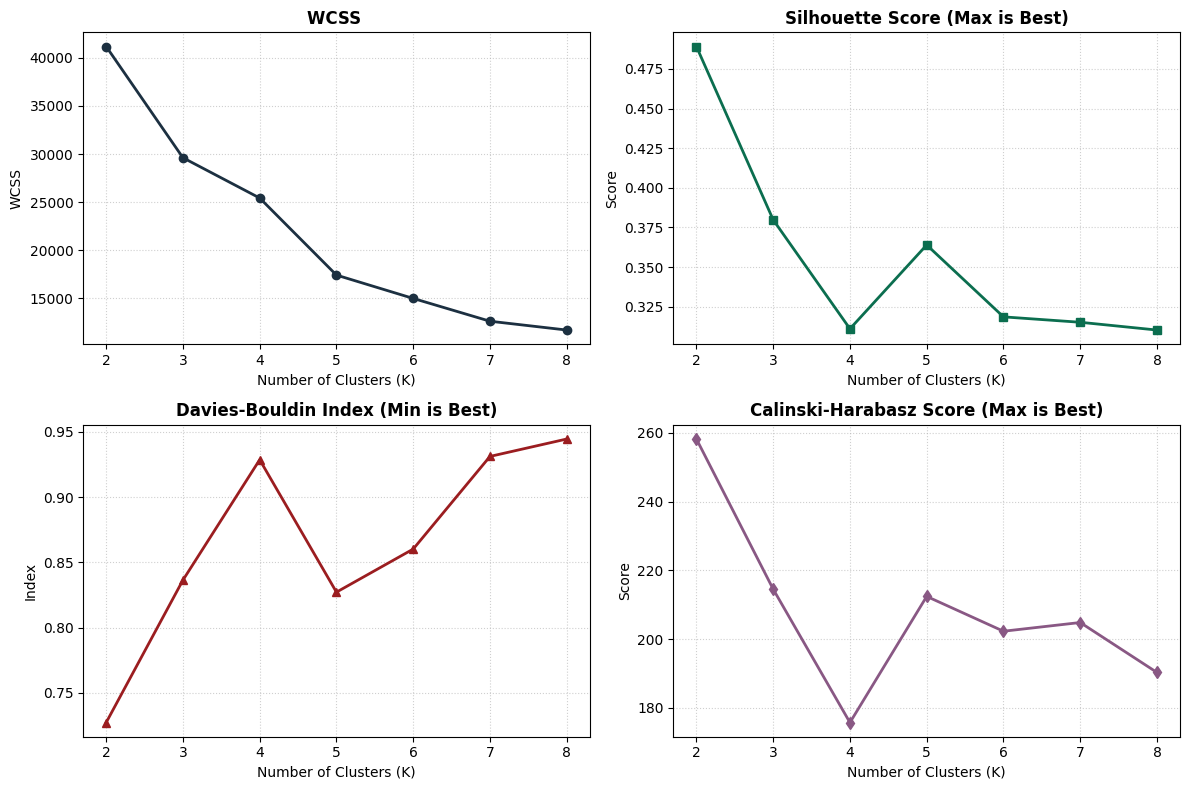

In [7]:

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

#  WCSS /Inertia (Elbow)
axs[0, 0].plot(K, wcss, marker="o", color="#1C3041", linewidth=2)
axs[0, 0].set_title("WCSS ", fontweight="bold")
axs[0, 0].set_xlabel("Number of Clusters (K)")
axs[0, 0].set_ylabel("WCSS")
axs[0, 0].grid(True, linestyle=":", alpha=0.6)

# Silhouette Score (Higher = Better)
axs[0, 1].plot(K, sh_scores, marker="s", color="#0B6E4F", linewidth=2)
axs[0, 1].set_title("Silhouette Score (Max is Best)", fontweight="bold")
axs[0, 1].set_xlabel("Number of Clusters (K)")
axs[0, 1].set_ylabel("Score")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)

#  Davies-Bouldin Index (Lower = Better)
axs[1, 0].plot(K, db_scores, marker="^", color="#9B1D20", linewidth=2)
axs[1, 0].set_title("Davies-Bouldin Index (Min is Best)", fontweight="bold")
axs[1, 0].set_xlabel("Number of Clusters (K)")
axs[1, 0].set_ylabel("Index")
axs[1, 0].grid(True, linestyle=":", alpha=0.6)

# Calinski-Harabasz Score (Higher = Better)
axs[1, 1].plot(K, ch_scores, marker="d", color="#895884", linewidth=2)
axs[1, 1].set_title("Calinski-Harabasz Score (Max is Best)", fontweight="bold")
axs[1, 1].set_xlabel("Number of Clusters (K)")
axs[1, 1].set_ylabel("Score")
axs[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

For the silhouette score, we obtain a Global Maximum for k=2 and a local maximum for K = 5

For davies boulding, the minimum value is reached for K = 2 with a local minimum for K = 5.

The Calinski-Harabasz score shows a maximum value for K=2, with a local maximum for K = 5

For the elbow method, we can see that this drop is mainly seen from K = 4 to K = 5, suggesting this is a better approach.

Additionally, despite k=5 being local maxima or minima compared to K=2 which is a global, we see that k=3 yields reasonable results and slightly better than K=5.

We will perform PCA analysis with the different clustering classes to see if data is being correctly grouped

##  PCA

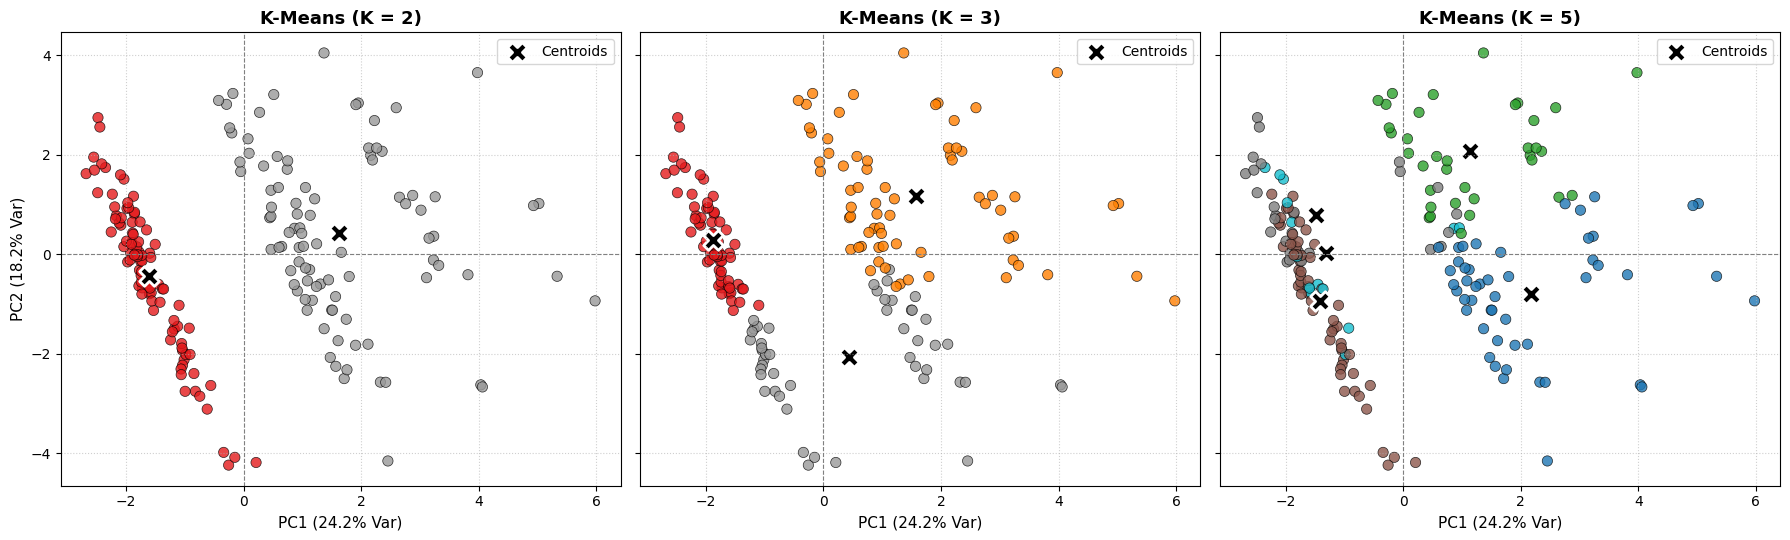

In [8]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(scaled_data)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 5]

for i, k in enumerate(k_values):
    ax = axs[i]
    kmeans = KMeans(n_clusters=k, random_state=42, init="k-means++", n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    # Project cluster centroids to the 2D PCA space
    centers_2d = pca_2d.transform(kmeans.cluster_centers_)

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot projected centroids
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Centroids",
    )

    ax.set_title(f"K-Means (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

As we can see, we would expect K=3, to split each of the vertical regions, however, this is not the case. K=5 shows a strange split, therefore, we will not use it.

Overall, due to the different metrics the best option will be K=2.

WCSS seems to lower at every value of K with no clear elbow. Its silhouette score is the highest, with around a 25% increase with respect to the second best option (K=3), for Calinski-Harabasz it also shows the highest value with a 20% increase to the second. Finally, it is the minimum for Davies-Bouldin. Therefore, looking at it from a mathematical point of view K=2 seems like the best option.

One thing which seems strange is that the PCA seems to show 3 different vertical lines. However, K=3 does not make this split correctly (other methods such as HDBSCAN,Spectral Clustering or Gaussian Mixture were used, but results were the same), this is because the first two components only show about 42% of the total data which is why we may think the natural split would be three clusters. Just in case, we will make a 3D PCA plot, to see how our split looks

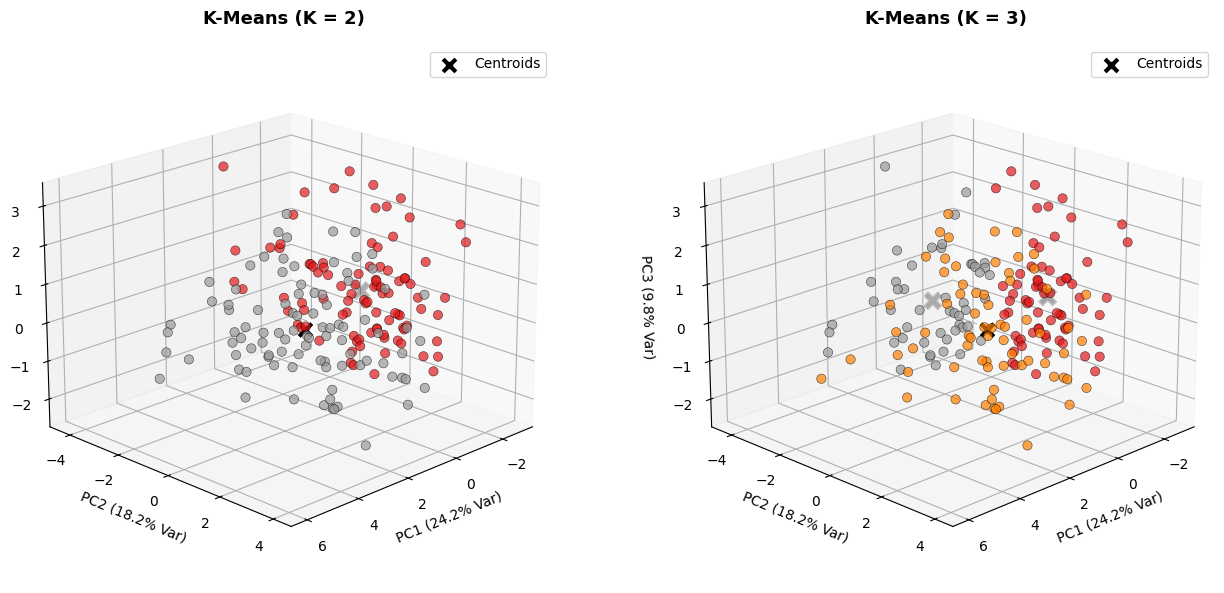

In [9]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

pca_3d = PCA(n_components=3)
x_pca_3d = pca_3d.fit_transform(scaled_data)
var_exp = pca_3d.explained_variance_ratio_ * 100

# Set up 3D subplots
fig = plt.figure(figsize=(20, 6))
k_values = [2, 3]

for i, k in enumerate(k_values):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    kmeans = KMeans(n_clusters=k, random_state=42, init="k-means++", n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    # Project cluster centroids into 3D PCA space
    centers_3d = pca_3d.transform(kmeans.cluster_centers_)

    # Scatter plot data points
    ax.scatter(
        x_pca_3d[:, 0],
        x_pca_3d[:, 1],
        x_pca_3d[:, 2],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=45,
        alpha=0.7,
        edgecolors="k",
        linewidths=0.4,
    )

    # Plot projected centroids
    ax.scatter(
        centers_3d[:, 0],
        centers_3d[:, 1],
        centers_3d[:, 2],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Centroids",
        zorder=10,
    )

    ax.set_title(f"K-Means (K = {k})", fontsize=13, fontweight="bold", pad=15)
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=10)
    ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=10)
    ax.set_zlabel(f"PC3 ({var_exp[2]:.1f}% Var)", fontsize=10)

    # Optimize initial viewing angle for readability
    ax.view_init(elev=20, azim=45)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Survival Function

We will now apply both Kaplan-Meier and Cox Regression using the survival library lifelines.

`Kaplan-Meier`: Non-parametric method which makes no assumption about the underlying distribution of data.
It uses the distinct event times, as well as the number of subjects who experience the event at time T, the patients still at risk, and finally the censored patients to compute the probability of survivong past $T_j$

`Cox-Regression`: Semi-parametric method as the distribution of the outcome remains unknown even if it is based on a parametric regression mode. Cox proposes a partial likelihood which depends only on the coefficients vector

In [16]:
y = pd.concat([event,duration], axis = 1)
y

,survival_status,survival_time
0,0,999
1,1,163
2,1,435
3,1,53
4,0,2043
...,...,...
182,1,385
183,1,634
184,0,1895
185,1,382


In [17]:
# We first split data K=2
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

model = KMeans(n_clusters=2, random_state=42, init="k-means++")
cluster_labels = model.fit_predict(scaled_data)

# Splitting data into separate groups
df = pd.DataFrame(data).copy()
df["cluster"] = cluster_labels
df["event"] = y["survival_status"]
df["duration"] = y["survival_time"]


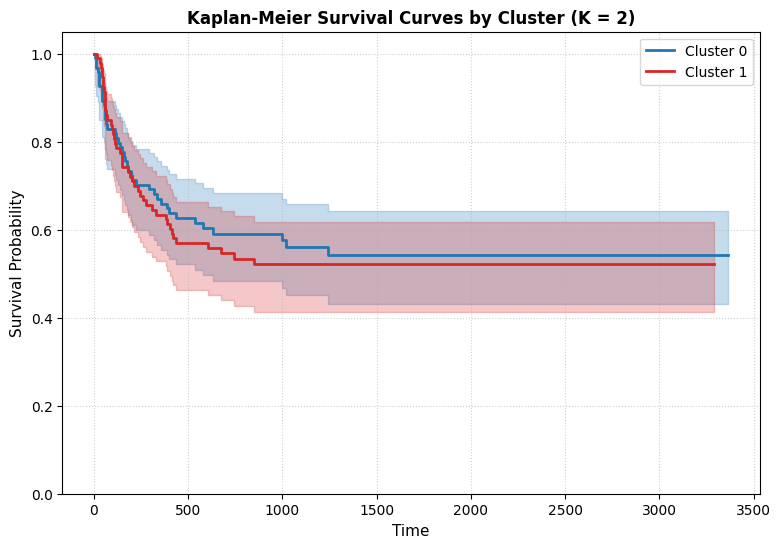

In [19]:
kmf0 = KaplanMeierFitter()
kmf1 = KaplanMeierFitter()

group0 = df[df["cluster"] == 0]
group1 = df[df["cluster"] == 1]

kmf0.fit(
    durations=group0["duration"],
    event_observed = group0["event"],
    label="Cluster 0"
)

kmf1.fit(
    durations=group1["duration"],
    event_observed = group1["event"],
    label="Cluster 1"
)

plt.figure(figsize=(9, 6))
ax = kmf0.plot_survival_function(ci_show=True, color="#1f77b4", lw=2)
kmf1.plot_survival_function(ax=ax, ci_show=True, color="#d62728", lw=2)

plt.title("Kaplan-Meier Survival Curves by Cluster (K = 2)", fontweight="bold")
plt.xlabel("Time", fontsize=11)
plt.ylabel("Survival Probability", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.ylim(0, 1.05)
plt.show()


There does not seem to be a significant difference in the survival functions of the different groups. *Clustering is not adequate?? I dont know if this is expected*

In [ ]:
# Applying regularized Cox model, treats cluster as a variable it works on,
#  result is similar if we fit independent models
# lasso is with l1_ratio = 1, ridge is with l1_ratio = 0, elastic net is 0.5
cph = CoxPHFitter(penalizer=0.1, l1_ratio=0.5)
cph.fit(df, duration_col="duration", event_col="event")

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>

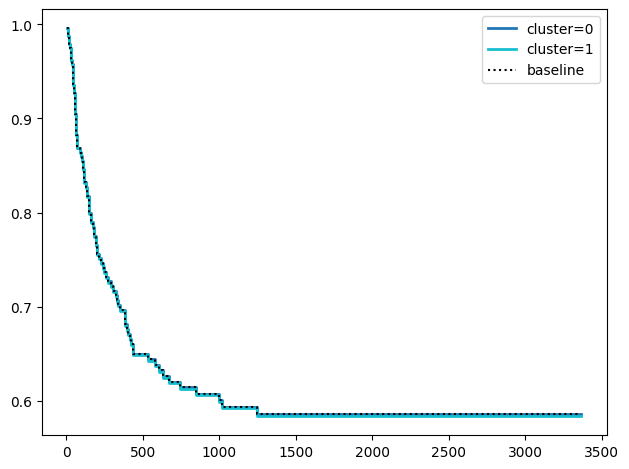

In [34]:
cph.plot_partial_effects_on_outcome(
    covariates="cluster",
    values=[0, 1],
    cmap="tab10",
    lw=2,
)

plt.tight_layout()
plt.show()

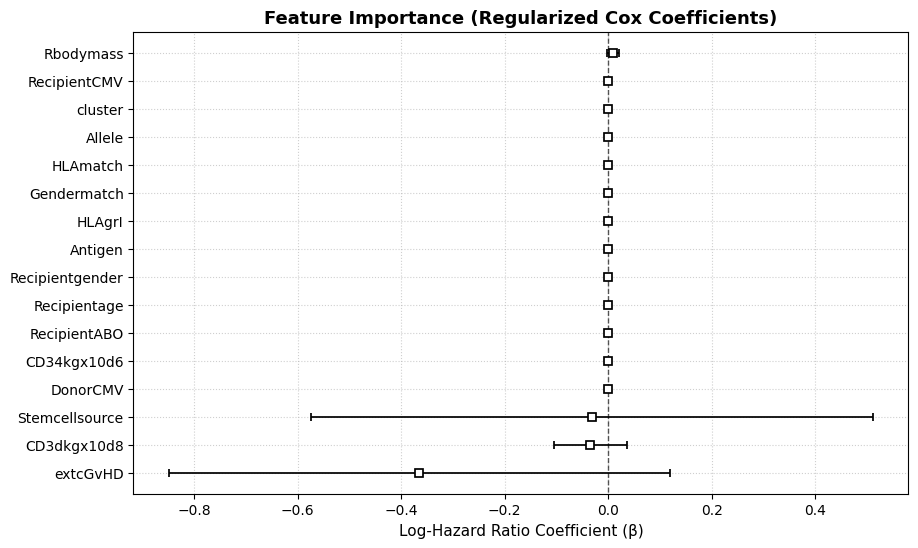

In [25]:
# Feature Importance
plt.figure(figsize=(10, 6))
cph.plot()
plt.title(
    "Feature Importance (Regularized Cox Coefficients)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Log-Hazard Ratio Coefficient (β)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

Survival groups seem to have no actual impact, additionally, many of the coefficients have a value of 0 meaning they are not really significant in our model. This is actually introducing noise in the model which could be a reason KMeans is nto correct.